# Notebook testi

Tämä notebook on testi, jonka tarkoituksena on kokeilla saanko tämän notebookin toimimaan selaimessa, ja saanko grafiikoita toimimaan. Tarkoituksena on myös selvittää, voiko soluja ajaa normaaliin tapaan selaimessa ja voiko niitä muokata itse. Notebookin rakentamisessa olen käyttänyt Jupyterin templaattia: [templaatti](https://jupyterlite.readthedocs.io/en/stable/quickstart/deploy.html) ja apuna Chat-GPT:tä.

Notebookiin saadaan upotettua kaikenlaista mediaa, kuten esimerkiksi
- Videoita
- Kuvia
- Ääntä

# Lähdetään liikkeelle esittämällä muutama kvanttitila:

$$ |\psi_1\rangle = |0\rangle = \begin{bmatrix} 1 \\ 0   \end{bmatrix}$$

$$ |\psi_2\rangle = \frac{1}{\sqrt{2}}( |0\rangle + |1\rangle ) = \frac{1}{\sqrt{2}}\begin{bmatrix} 1 \\ 1   \end{bmatrix}$$

$$ |\psi_3\rangle = \frac{1}{\sqrt{2}}( |0\rangle + i |1\rangle ) = \frac{1}{\sqrt{2}}\begin{bmatrix} 1 \\ i   \end{bmatrix}$$

Nämä tilat voidaan kirjoittaa kolmpeksivektoreina Pythonilla käyttämällä `numpy`-kirjastoa

In [18]:
import numpy as np

psi1 = np.array([ 1, 0 ])
psi2 = [ 1/np.sqrt(2), 1/np.sqrt(2) ]      
psi3 = [ 1/np.sqrt(2), 1j/np.sqrt(2) ]

print(psi1)
print(psi2)
print(psi3)

[1 0]
[np.float64(0.7071067811865475), np.float64(0.7071067811865475)]
[np.float64(0.7071067811865475), 0.7071067811865475j]


`numpy` on Pythonin kirjasto numeerista laskentaa varten. Sillä onnistuu lineaarialgebra.

## Esimerkki 1: Seuraavaksi esitellään satunnaista dataa

Tässä esimerkissä kuvataan satunnaista dataa. Satunnainen data generoidaan `numpy`:n avulla, ja kuvaaja piirretään kirjaston `matplotlib`avulla. Kokeile tehdä muutoksia kuvaajaan.

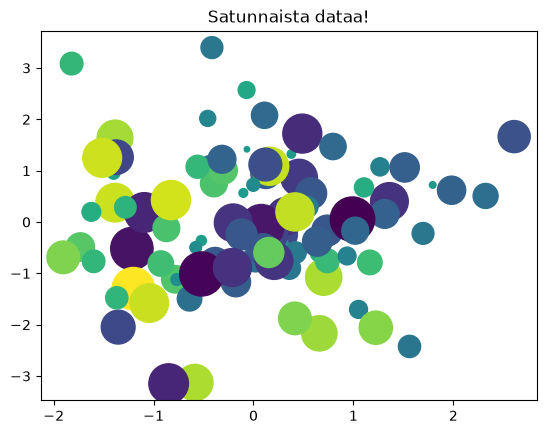

In [19]:
import numpy as np
from matplotlib import pyplot as plt

# Luodaan 100 satunnaista datapistettä muodossa (x_i, y_i, scale)
x, y, scale = np.random.randn(3, 100)
fig, ax = plt.subplots() # liittyy kuvaajan piirtämiseen

# Piirretään datapisteet kuvaajaan
ax.scatter(x=x, y=y, c=scale, s=np.abs(scale) * 500)
ax.set(title="Satunnaista dataa!")
plt.show()


## Esimerkki 2: Kubitin mittaus

Kubitin tila ilmoitetaan tilavektorina

$$
|\psi\rangle = \cos\left(\frac{\theta}{2}\right)|0\rangle
+ e^{i\phi}\sin\left(\frac{\theta}{2}\right)|1\rangle
$$

Mittaustulosten todennäköisyydet ovat

$$
P(0) = \left|\cos\left(\frac{\theta}{2}\right)\right|^2
$$

ja

$$
P(1) = \left|e^{i\phi}\sin\left(\frac{\theta}{2}\right)\right|^2
$$

Muuta kulmia ja katso, mitä mittaustodennäköisyyksille tapahtuu.

In [ ]:
%pip install ipywidgets

In [20]:
import numpy as np
import ipywidgets as widgets
from matplotlib import pyplot as plt
from IPython.display import display, clear_output

def probabilities(theta, phi):
    p0 = np.cos(theta / 2)
    p1 = np.exp(1j * phi) * np.sin(theta / 2)

    P0 = np.abs(p0)**2
    P1 = np.abs(p1)**2

    return P0, P1

slider_theta = widgets.FloatSlider(
    value=np.pi / 2,
    min=0,
    max=np.pi,
    step=0.01,
    description='theta:',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='.2f',
)

slider_phi = widgets.FloatSlider(
    value=0,
    min=0,
    max=2 * np.pi,
    step=0.01,
    description='phi:',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='.2f',
)

output = widgets.Output()

def update_plot(theta, phi):
    P0, P1 = probabilities(theta, phi)

    with output:
        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(6, 3))

        ax.bar(['0', '1'], [P0, P1])
        ax.set_ylim(0, 1)
        #ax.set_ylabel('xx')
        ax.set_title('Mittaustulosten todennäköisyys')

        for i, p in enumerate([P0, P1]):
            ax.text(i, p + 0.03, f'{p:.3f}', ha='center')

        plt.show()
        plt.close(fig)

ui = widgets.VBox([slider_theta, slider_phi])

widgets.interactive_output(
    update_plot,
    {'theta': slider_theta, 'phi': slider_phi}
)

display(ui, output)

Output()

## Esimerkki 3: Kvanttikerneli

1. Koodataan klassiset datapisteet kvanttitilaan.
2. Verrataan kvanttitiloja toisiinsa ja esitetään niiden samankaltaisuus luvuilla 0–1.

Koodataan $x_1$ ja $x_2$ yhden kubitin tilaan:

$$|\psi(x)\rangle =\cos\left(\frac{x_1}{2}\right)|0\rangle+ e^{i\gamma x_2}\sin\left(\frac{x_1}{2}\right)|1\rangle$$

Kvanttikerneli:

$$K(x_i,x_j) =\left|\langle\psi(x_i)|\psi(x_j)\rangle\right|^2$$

Muuta parametrejä ja tarkastele, miten ne vaikuttavat kvanttitilojen samankaltaisuuteen.

In [22]:
# Importit ja data

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# Luodaan 16 datapistettä
x1_values = np.linspace(0.3, 2.8, 4) # (alku, loppu, määrä)
x2_values = np.linspace(0, 2*np.pi, 4, endpoint=False)

# Kaikki pisteiden yhdistelmät
X_list = []

for x1 in x1_values:
    for x2 in x2_values:
        X_list.append([x1, x2])

X = np.array(X_list)

print("Datapisteiden määrä:", len(X))

Datapisteiden määrä: 16


In [23]:
# Kvanttiominaisuuskartta

def quantum_state(x, gamma):
    x1, x2 = x

    alpha = np.cos(x1 / 2)
    beta = np.exp(1j * gamma * x2) * np.sin(x1 / 2)

    return np.array([alpha, beta])


def quantum_kernel(x1, x2, gamma):
    state1 = quantum_state(x1, gamma)
    state2 = quantum_state(x2, gamma)

    overlap = np.vdot(state1, state2)

    return np.abs(overlap)**2

In [24]:
# Kvanttikerneli

def calculate_kernel_matrix(X, gamma):
    n = len(X)
    K = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            K[i, j] = quantum_kernel(X[i], X[j], gamma)

    return K

In [ ]:
gamma_slider = widgets.FloatSlider(
    value=1.0,
    min=0,
    max=3,
    step=0.1,
    description='Gamma:',
    continuous_update=False,
    readout_format='.1f'
)

point_selector = widgets.Dropdown(
    options=[(f"Piste {i+1}", i) for i in range(len(X))],
    value=0,
    description='Valitse piste:'
)

output = widgets.Output()


def update_visualisation(gamma, selected):

    K = calculate_kernel_matrix(X, gamma)

    with output:
        clear_output(wait=True)

        fig, axes = plt.subplots(1, 2, figsize=(11, 4))

        # Kernelimatriisi
        im = axes[0].imshow(
            K,
            cmap='viridis',
            vmin=0,
            vmax=1
        )

        axes[0].set_title('Kvanttikernelimatriisi')
        axes[0].set_xlabel('Datapiste')
        axes[0].set_ylabel('Datapiste')
        axes[0].set_xticks(range(len(X)))
        axes[0].set_yticks(range(len(X)))

        fig.colorbar(im, ax=axes[0], label='Samankaltaisuus')

        # Vertaa datapisteisiin (samankaltaisuus)
        axes[1].bar(
            range(1, len(X)+1),
            K[selected],
        )

        axes[1].set_ylim(0, 1)
        axes[1].set_xlabel('Datapiste')
        axes[1].set_ylabel('Samankaltaisuus')
        axes[1].set_title(f'Samankaltaisuus verrattuna pisteeseen {selected+1}')

        plt.tight_layout()
        plt.show()
        plt.close(fig)


def on_change(change):
    update_visualisation(
        gamma_slider.value,
        point_selector.value
    )


gamma_slider.observe(on_change, names='value')
point_selector.observe(on_change, names='value')

display(widgets.VBox([
    gamma_slider,
    point_selector
]))

display(output)

update_visualisation(
    gamma_slider.value,
    point_selector.value
)

Output()